# Step 5: Modeling the distance vs. accuracy trade-off

**Question:** At Torrey Pines, is it more rewarding to hit it farther and miss more fairways, or hit it shorter and find more fairways? How does that compare with a typical PGA TOUR event?

**Approach:** OLS regression of strokes gained on driving distance and fairway %. We build it up in four steps, each fixing a weakness of the one before:

| Model | What it adds | Why |
|---|---|---|
| A | Separate regressions for Torrey and other events | The simplest version of the question |
| B | One pooled regression with Torrey *interactions* | Gives a formal test of "is Torrey different?" |
| C | + event fixed effects | Compares each player with the field *that week*, removing course and weather effects |
| D | + player fixed effects | Compares each player with *himself*, removing the "better players are both long and straight" confounding |

Model D is the one we trust most.

### 1. Load the data
Same file as Step 4. We keep rows with all three numbers we need. `torrey` is our 0/1 indicator for the Farmers Insurance Open.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

df = pd.read_csv("../data/clean/pga_event_stats.csv")
df = df.dropna(subset=["distance", "fairway_pct", "sg_total"]).copy()
df["torrey"] = df["is_torrey"]
print(f"{len(df):,} player-events; {df['torrey'].sum()} at Torrey")

25,558 player-events; 760 at Torrey


### 2. Standard errors: why "clustered by player"
OLS's default standard errors assume every row is independent. Here, the same player appears up to ~200 times, and his weeks are related (a player who putts well this week probably putts well next week). **Clustering by player** lets each player's rows be correlated with each other, which gives more honest (usually wider) confidence intervals. We use it in every model.

This small helper fits a model and prints just the coefficients we care about.

In [2]:
KEY = ["distance", "fairway_pct", "distance:torrey", "fairway_pct:torrey"]

def fit(formula, data):
    """Fit an OLS model with standard errors clustered by player."""
    return smf.ols(formula, data).fit(cov_type="cluster", cov_kwds={"groups": data["player_id"]})

def coef_table(model, names):
    """Coefficient, standard error and p-value for the listed variables."""
    names = [n for n in names if n in model.params.index]
    return pd.DataFrame({"coef": model.params[names], "std err": model.bse[names],
                         "p-value": model.pvalues[names]}).round(4)

### 3. Model A: separate regressions
$$\text{SG}_{\text{total}} = \beta_0 + \beta_1\,\text{distance} + \beta_2\,\text{fairway\%} + \varepsilon$$
fit once on Torrey rows and once on all other rows. $\beta_1$ = strokes gained per round for **one extra yard**, holding fairways fixed. $\beta_2$ = strokes gained per round for **one extra percentage point of fairways**, holding distance fixed.

In [3]:
model_a_tour = fit("sg_total ~ distance + fairway_pct", df[df.torrey == 0])
model_a_torrey = fit("sg_total ~ distance + fairway_pct", df[df.torrey == 1])
print("Other events:"); print(coef_table(model_a_tour, ["distance", "fairway_pct"]))
print("\nTorrey:");      print(coef_table(model_a_torrey, ["distance", "fairway_pct"]))

Other events:
              coef  std err  p-value
distance     0.016   0.0009      0.0
fairway_pct  0.022   0.0009      0.0

Torrey:
               coef  std err  p-value
distance     0.0301   0.0046      0.0
fairway_pct  0.0391   0.0063      0.0


Both stats matter in both places, and at Torrey **both** slopes are roughly twice as large. But Model A can't tell us whether the differences are real or just noise, and it doesn't account for who is playing or how hard the course played.

### 4. Model B: one pooled regression with interactions
`(distance + fairway_pct) * torrey` expands to distance + fairway_pct + torrey + distance×torrey + fairway_pct×torrey. The **interaction** terms (`distance:torrey`, `fairway_pct:torrey`) measure *how much the slope changes at Torrey*. If an interaction's p-value is small, Torrey really is different on that dimension.

In [4]:
model_b = fit("sg_total ~ (distance + fairway_pct) * torrey", df)
coef_table(model_b, KEY + ["torrey"])

,coef,std err,p-value
distance,0.0160,0.0009,0.0000
fairway_pct,0.0220,0.0009,0.0000
distance:torrey,0.0141,0.0046,0.0023
fairway_pct:torrey,0.0171,0.0063,0.0068
torrey,-4.9346,1.5270,0.0012


### 5. Model C: add event fixed effects
`C(tournament_id)` adds a separate intercept (a 0/1 dummy) for each of the ~400 events. That means every comparison is now **within the same week**: a player's distance and fairway % are compared with the rest of that week's field, so wind, rain, firm fairways or a soft course stop muddying the picture. (The plain `torrey` term drops out, because the Farmers dummies already cover it.)

In [5]:
model_c = fit("sg_total ~ distance + fairway_pct + distance:torrey + fairway_pct:torrey + C(tournament_id)", df)
coef_table(model_c, KEY)

,coef,std err,p-value
distance,0.0302,0.0017,0.0000
fairway_pct,0.0396,0.0014,0.0000
distance:torrey,0.0105,0.0052,0.0419
fairway_pct:torrey,0.0026,0.0062,0.6786


### 6. Model D: add player fixed effects (handling confounding)
**The confounding problem:** good players tend to be both long *and* accurate, and they're also good at everything else (approach shots, putting). In Models A–C, part of what looks like "the value of distance" is really "the value of being a better golfer".

`C(player_id)` gives each of the ~1,000 players his own intercept, a stand-in for his overall skill. Now the coefficients come only from **variation within a player**: when Rory hits it 10 yards longer than *his own* usual, how many more strokes does he gain? Skill no longer contaminates the estimate.

This is our preferred model.

In [6]:
model_d = fit("sg_total ~ distance + fairway_pct + distance:torrey + fairway_pct:torrey"
              " + C(tournament_id) + C(player_id)", df)
coef_table(model_d, KEY)

,coef,std err,p-value
distance,0.0233,0.0014,0.0000
fairway_pct,0.0370,0.0012,0.0000
distance:torrey,0.0099,0.0049,0.0441
fairway_pct:torrey,-0.0002,0.0061,0.9780


### 7. All four models side by side
For Torrey, the slope is the base slope plus the interaction (for example, Torrey's distance slope = `distance` + `distance:torrey`). We compute those combinations, with their standard errors, using the model's covariance matrix (`lincom` = "linear combination").

In [7]:
def lincom(model, weights):
    """Estimate and standard error of a weighted sum of coefficients, e.g. {'distance': 1, 'distance:torrey': 1}."""
    w = pd.Series(0.0, index=model.params.index)
    for name, value in weights.items():
        w[name] = value
    est = w @ model.params
    se = np.sqrt(w @ model.cov_params() @ w)
    return est, se

def slopes(model, interacted=True):
    """Per-yard and per-fairway-point slopes for tour and Torrey."""
    out = {}
    for var in ["distance", "fairway_pct"]:
        out[("Tour", var)] = lincom(model, {var: 1})
        out[("Torrey", var)] = lincom(model, {var: 1, f"{var}:torrey": 1}) if interacted else None
    return out

rows = []
specs = {"A: separate": None, "B: pooled": model_b, "C: + event FE": model_c, "D: + event & player FE": model_d}
for label, m in specs.items():
    for place in ["Tour", "Torrey"]:
        if m is None:
            mm = model_a_tour if place == "Tour" else model_a_torrey
            d, f = lincom(mm, {"distance": 1}), lincom(mm, {"fairway_pct": 1})
        else:
            s = slopes(m)
            d, f = s[(place, "distance")], s[(place, "fairway_pct")]
        rows.append({"model": label, "where": place,
                     "SG per +10 yards": f"{10*d[0]:.3f} ({10*d[1]:.3f})",
                     "SG per +1 pt fairways": f"{f[0]:.4f} ({f[1]:.4f})"})
comparison = pd.DataFrame(rows).set_index(["model", "where"])
comparison   # standard errors in parentheses

SG per +10 yards SG per +1 pt fairways
model                  where                                        
A: separate            Tour      0.160 (0.009)       0.0220 (0.0009)
                       Torrey    0.301 (0.046)       0.0391 (0.0063)
B: pooled              Tour      0.160 (0.009)       0.0220 (0.0009)
                       Torrey    0.301 (0.046)       0.0391 (0.0063)
C: + event FE          Tour      0.302 (0.017)       0.0396 (0.0014)
                       Torrey    0.407 (0.053)       0.0422 (0.0062)
D: + event & player FE Tour      0.233 (0.014)       0.0370 (0.0012)
                       Torrey    0.332 (0.048)       0.0368 (0.0061)

### 8. The trade-off in plain English
How many percentage points of fairways is **10 extra yards** worth? Set the two effects equal:
$$10 \times \beta_{\text{distance}} = X \times \beta_{\text{fairway}} \quad\Rightarrow\quad X = \frac{10\,\beta_{\text{distance}}}{\beta_{\text{fairway}}}$$
A ratio of two estimates has its own uncertainty. We get a 95% confidence interval with the **delta method**: a first-order Taylor approximation (calculus!) of how errors in the two coefficients pass through the ratio.

In [8]:
def tradeoff(model, place, yards=10):
    """Fairway percentage points that `yards` of extra distance is worth, with a 95% CI (delta method)."""
    t = 1 if place == "Torrey" else 0
    wd = pd.Series(0.0, index=model.params.index); wd["distance"] = 1
    wf = pd.Series(0.0, index=model.params.index); wf["fairway_pct"] = 1
    if t:
        wd["distance:torrey"] = 1; wf["fairway_pct:torrey"] = 1
    V = model.cov_params()
    bd, bf = wd @ model.params, wf @ model.params
    cov2 = np.array([[wd @ V @ wd, wd @ V @ wf], [wf @ V @ wd, wf @ V @ wf]])
    ratio = yards * bd / bf
    grad = np.array([yards / bf, -yards * bd / bf**2])     # derivative of the ratio
    se = np.sqrt(grad @ cov2 @ grad)
    return ratio, ratio - 1.96 * se, ratio + 1.96 * se

trade = pd.DataFrame(
    [(label, place, *tradeoff(m, place)) for label, m in [("C: + event FE", model_c), ("D: + event & player FE", model_d)]
     for place in ["Tour", "Torrey"]],
    columns=["model", "where", "10 yards = X pts of fairways", "95% CI low", "95% CI high"]).round(1)
trade

,model,where,10 yards = X pts of fairways,95% CI low,95% CI high
0,C: + event FE,Tour,7.6,6.7,8.5
1,C: + event FE,Torrey,9.6,6.5,12.8
2,D: + event & player FE,Tour,6.3,5.5,7.1
3,D: + event & player FE,Torrey,9.0,5.7,12.3


In [9]:
r_tour, lo_tour, hi_tour = tradeoff(model_d, "Tour")
r_torrey, lo_torrey, hi_torrey = tradeoff(model_d, "Torrey")
print(f"On tour:   10 yards of distance is worth about {r_tour:.1f} percentage points of fairways (95% CI {lo_tour:.1f} to {hi_tour:.1f}).")
print(f"At Torrey: 10 yards of distance is worth about {r_torrey:.1f} percentage points of fairways (95% CI {lo_torrey:.1f} to {hi_torrey:.1f}).")

On tour:   10 yards of distance is worth about 6.3 percentage points of fairways (95% CI 5.5 to 7.1).
At Torrey: 10 yards of distance is worth about 9.0 percentage points of fairways (95% CI 5.7 to 12.3).


### 9. Robustness: does the result hold for other strokes-gained measures?
SG: Total includes putting, which has nothing to do with driving and adds noise. **SG: Off-the-Tee** isolates the drive itself, and **SG: Tee-to-Green** covers everything except putting. If the Torrey pattern shows up there too, we can trust it more.

In [10]:
robust = {}
for outcome in ["sg_total", "sg_t2g", "sg_ott"]:
    d = df.dropna(subset=[outcome])
    m = fit(f"{outcome} ~ distance + fairway_pct + distance:torrey + fairway_pct:torrey"
            " + C(tournament_id) + C(player_id)", d)
    robust[outcome] = coef_table(m, KEY)
pd.concat(robust, axis=1)

sg_total                  sg_t2g                  sg_ott  \
                       coef std err p-value    coef std err p-value    coef   
distance             0.0233  0.0014  0.0000  0.0231  0.0011  0.0000  0.0211   
fairway_pct          0.0370  0.0012  0.0000  0.0420  0.0011  0.0000  0.0398   
distance:torrey      0.0099  0.0049  0.0441  0.0111  0.0046  0.0152  0.0107   
fairway_pct:torrey  -0.0002  0.0061  0.9780 -0.0045  0.0050  0.3631 -0.0077   

                                    
                   std err p-value  
distance            0.0006  0.0000  
fairway_pct         0.0005  0.0000  
distance:torrey     0.0017  0.0000  
fairway_pct:torrey  0.0020  0.0001

### 10. Chart: what 10 yards and 5 fairway points are worth, tour vs. Torrey
Estimates from Model D, with 95% confidence intervals. We compare **+10 yards** with **+5 percentage points of fairways** because those are similar-sized, realistic changes for a player (roughly 0.7 and 0.5 standard deviations).

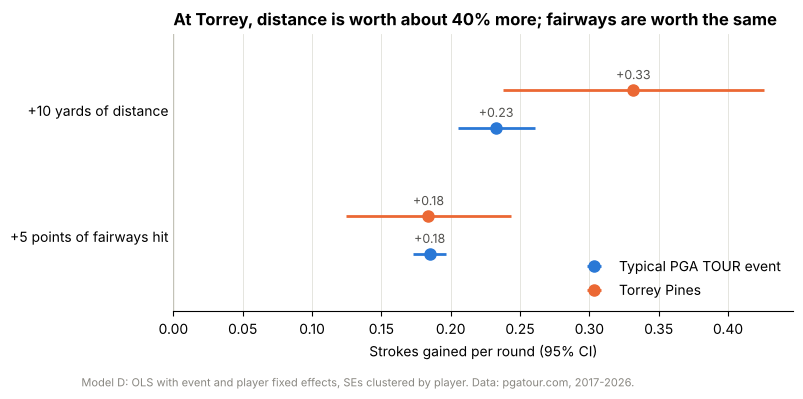

In [11]:
TOUR, TORREY = "#2a78d6", "#eb6834"     # blue = typical tour event, orange = Torrey
s = slopes(model_d)
items = [("+10 yards of distance", "distance", 10), ("+5 points of fairways hit", "fairway_pct", 5)]

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (label, var, size) in enumerate(items):
    for j, (place, color, name) in enumerate([("Tour", TOUR, "Typical PGA TOUR event"), ("Torrey", TORREY, "Torrey Pines")]):
        est, se = s[(place, var)]
        y = i + (0.15 if j == 0 else -0.15)
        ax.errorbar(size * est, y, xerr=1.96 * size * se, fmt="o", color=color, markersize=8,
                    elinewidth=2, capsize=0, label=name if i == 0 else None)
        ax.annotate(f"{size*est:+.2f}", (size * est, y), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=9, color="#52514e")
ax.set_yticks([0, 1]); ax.set_yticklabels([it[0] for it in items])
ax.set_ylim(-0.6, 1.6); ax.invert_yaxis()
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlim(left=0)
ax.set_xlabel("Strokes gained per round (95% CI)")
ax.grid(axis="x", color="#e1e0d9", linewidth=0.6); ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="lower right")
ax.set_title("At Torrey, distance is worth about 40% more; fairways are worth the same",
             loc="left", fontsize=12, fontweight="bold")
fig.text(0.01, -0.1, "Model D: OLS with event and player fixed effects, SEs clustered by player. "
         "Data: pgatour.com, 2017-2026.", fontsize=8, color="#898781")
fig.savefig("../figures/02_value_of_distance_vs_fairways.png", dpi=200, bbox_inches="tight")
plt.show()

### 11. Interpretation
**Answer to the question:** At Torrey Pines, **distance is the better bet**. In our preferred model (D):

- **On a typical PGA TOUR event**, 10 extra yards is worth about as much as hitting ~6 more percentage points of fairways.
- **At Torrey**, 10 extra yards is worth about as much as ~9 more percentage points of fairways. Each yard is worth roughly 40% more there (the `distance:torrey` interaction is positive, p ≈ 0.04), while a fairway point is worth about the same as anywhere else (interaction ≈ 0, p ≈ 0.98).
- **How sure are we?** The extra value of a yard at Torrey is statistically significant (p ≈ 0.04), but only just. The trade-off ratio itself has a wide interval at Torrey (about 6 to 12 points), which overlaps the tour's (about 5.5 to 7). So the honest summary is "distance is worth more at Torrey, and the evidence is moderate".
- **The off-the-tee result is even sharper:** with SG: Off-the-Tee as the outcome, the extra value of distance at Torrey is highly significant, and fairways are actually worth *less* there than on tour. That fits Torrey South's length (one of the longest courses on tour) and its rough. Everyone misses fairways there, so the cost of a miss is shared by the field, while extra length shortens long approach shots.

**How the controls changed things:** adding event fixed effects (C) roughly doubled the tour slopes, because comparing players within the same week removes course-to-course noise. Adding player fixed effects (D) shrank the distance slope by about a quarter, which is the confounding we expected: part of the raw "distance premium" was really "better players are longer".

**Caveats** (more in the README):
- The Torrey estimates rest on 760 player-events from 10 tournaments, so the intervals are wide.
- The data mostly covers players who made the cut, which cuts off the worst weeks and probably shrinks all the slopes.
- Torrey strokes gained comes only from rounds on the South Course (3 of 4 rounds), while distance and fairways may include the North Course round.
- Within-player variation in distance and accuracy partly reflects how well a player is swinging that week, not just strategy, so these are associations, not proof of what would happen if a player changed his approach.